## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

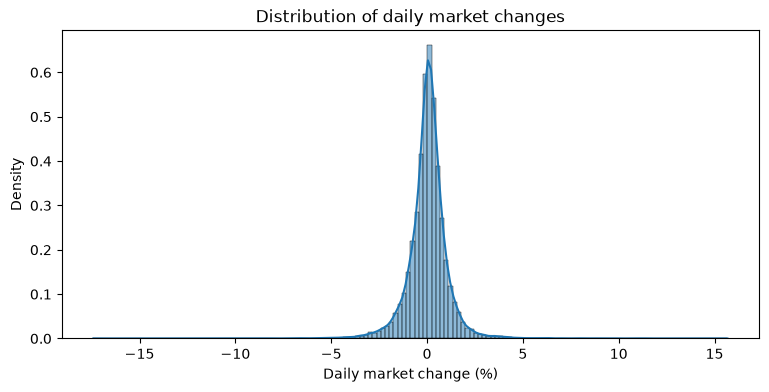

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

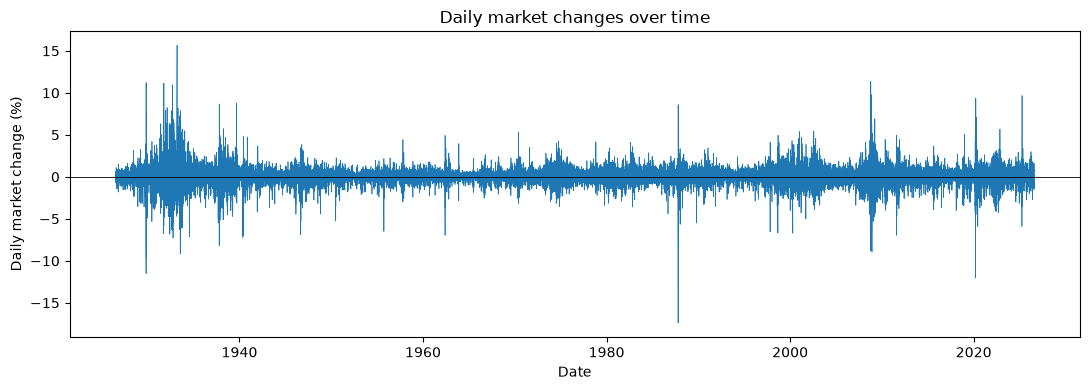

In [10]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
>Up transitions are more common. 0.32 vs 0.22
- Are you more likely to transition to an Up day from a Down or Up day?
> You are more likely to transition to an up day after an up day. 0.58 vs 0.5. 

In [11]:
df['x_t'] = df['market_return_pct']
df['x_tp1'] = df['x_t'].shift(-1)
df['s_t'] = np.where(df['x_t'] > 0, 'Up', 'Down')
df['s_tp1'] = np.where(df['x_tp1'] > 0, 'Up', 'Down')
pairs = df.dropna(subset=['x_tp1']) 

joint = pd.crosstab(pairs['s_t'], pairs['s_tp1'], normalize=True)
print(joint, joint.sum(axis=1), joint.sum(axis=0), sep='\n\n')

cond = pd.crosstab(pairs['s_t'], pairs['s_tp1'], normalize='index')
print(cond)

s_tp1      Down        Up
s_t                      
Down   0.224720  0.228142
Up     0.228142  0.318996

s_t
Down    0.452862
Up      0.547138
dtype: float64

s_tp1
Down    0.452862
Up      0.547138
dtype: float64
s_tp1      Down        Up
s_t                      
Down   0.496221  0.503779
Up     0.416974  0.583026


### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
> Small gain is the most common. Large loss are the least common. 
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
> Most likely tranistions are small gain --> small gain 0.16. and small gain <--> small loss 0.10.
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
>For every current state, the top two next states are small gain and small loss. The rows are close to marginal distribution, not uniform, so next state is hard to predict.
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 
>The min and max and standard deviation are largest after a large loss and large gain. Theyre the smallest after calm days. Volitility clusters and more so after losses. 

>Tomorrow’s mean ranges from −0.04 after losses to +0.16 after large gain, vs an overall mean of 0.043.

In [12]:
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf]
df['b_t'] = pd.cut(df['x_t'], bins=bins, labels=labels) 
df['b_tp1'] = df['b_t'].shift(-1)
pairs = df.dropna(subset=['x_tp1'])

df['b_t'].value_counts().reindex(labels)

joint5 = pd.crosstab(pairs['b_t'], pairs['b_tp1'], normalize=True)
joint5.sum(axis=1), joint5.sum(axis=0)
joint5.stack().sort_values(ascending=False).head(5)

cond5 = pd.crosstab(pairs['b_t'], pairs['b_tp1'], normalize='index')

pairs.groupby('b_t', observed=True)['x_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
b_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


In [13]:
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['b_t'] = pd.cut(df['x_t'], [-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=labels)
df['b_tp1'] = df['b_t'].shift(-1)
pairs = df.dropna(subset=['x_tp1'])

display(df['b_t'].value_counts(sort=False))
display(pd.crosstab(pairs['b_t'], pairs['b_tp1'], normalize=True, margins=True))
display(pd.crosstab(pairs['b_t'], pairs['b_tp1'], normalize='index'))
pairs.groupby('b_t', observed=True)['x_tp1'].describe()

b_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

b_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
b_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


b_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
b_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


,count,mean,std,min,25%,50%,75%,max
b_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
> The heatmap is flat. Minus uniform, it shoes hot corners which means that extreme days are followed by extreme days in either direction. 
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
> It has the same patter. Extreme rows are around 3 times uniform in the corners, and middle rows are near uniform. 

>Middle rows are about 1.2x uniform in the center and 0.4x in the corners, so calm days follow calm days.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
> The mean is flat near 0 with a small upward slope. The min and max fan out at both ends. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
>It is U shaped, higher after losses. About 2.1 after the worst bin, 1.7 after the best, about 0.83 in the middle 
- How easy is it to predict the market?
>The direction is pretty much unpredictable. However volatility is fairly predictable. Overall, I would probably not try this.

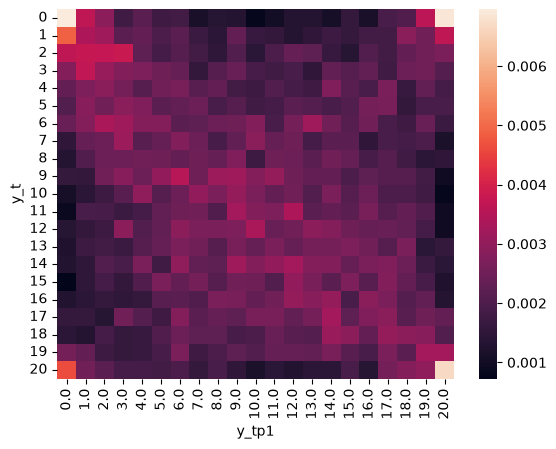

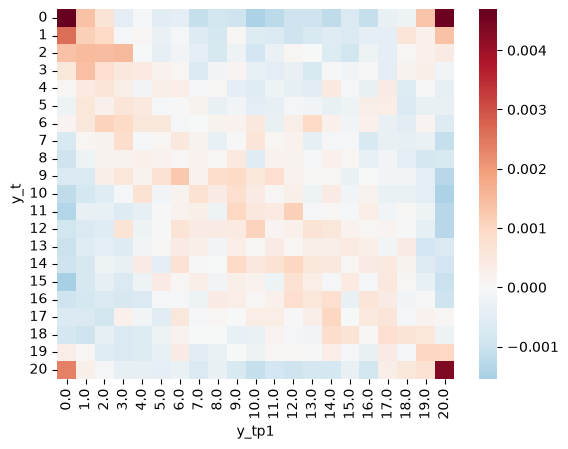

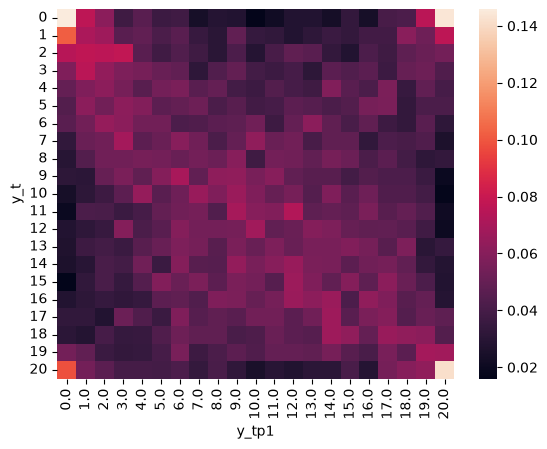

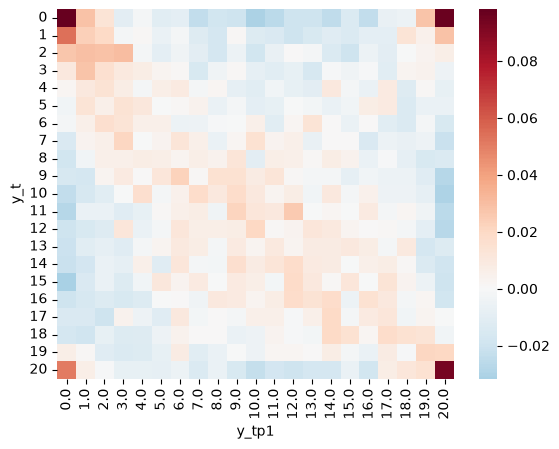

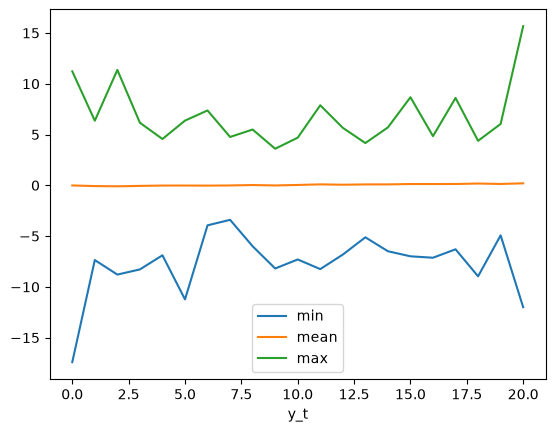

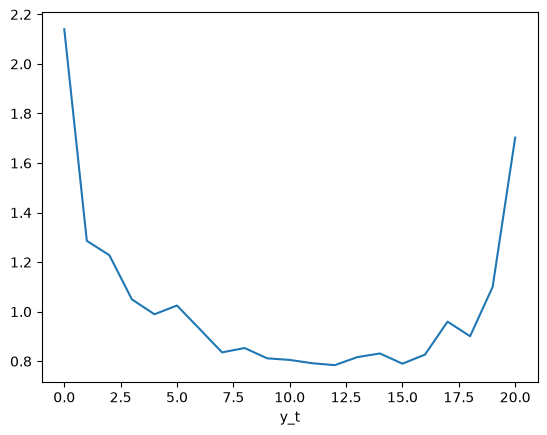

In [14]:
K = 21
df['y_t'] = pd.qcut(df['market_return_pct'], K, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['x_tp1'] = df['market_return_pct'].shift(-1)

joint = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
cond = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')

sns.heatmap(joint); plt.show()
sns.heatmap(joint - 1/K**2, cmap='RdBu_r', center=0); plt.show()
sns.heatmap(cond); plt.show()
sns.heatmap(cond - 1/K, cmap='RdBu_r', center=0); plt.show()

stats = df.groupby('y_t')['x_tp1'].agg(['min', 'mean', 'max', 'std'])
stats[['min', 'mean', 'max']].plot(); plt.show()
stats['std'].plot(); plt.show()